In [1]:
# CELL 1 — Instalasi library
%pip install -q ucimlrepo

In [2]:
# CELL 2 — Import library
import json
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay
)

sns.set_theme()
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42


In [3]:
# CELL 3 — Ambil dataset asli dari UCI
# UCI Machine Learning Repository dataset ID 350.
dataset = fetch_ucirepo(id=350)
X_raw = dataset.data.features
y_raw = dataset.data.targets
print("Ukuran fitur:", X_raw.shape)
print("Ukuran target:", y_raw.shape)
display(X_raw.head())
display(y_raw.head())


Ukuran fitur: (30000, 23)
Ukuran target: (30000, 1)


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679


,Y
0,1
1,1
2,0
3,0
4,0


In [4]:
# CELL 4 — Rapikan nama fitur dan target
feature_names = [
    "LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE",
    "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6",
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"
]
if X_raw.shape[1] != len(feature_names):
    raise ValueError(f"Jumlah fitur ditemukan {X_raw.shape[1]}, diharapkan {len(feature_names)}.")

X = X_raw.copy()
X.columns = feature_names
y = y_raw.iloc[:, 0].astype(int).rename("default_next_month")
df = X.copy()
df["default_next_month"] = y.to_numpy()
print("Ukuran dataset:", df.shape)
display(df.head())


Ukuran dataset: (30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default_next_month
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [5]:
# CELL 5 — Periksa struktur dan kualitas data
df.info()
display(df.describe().T)
print("Nilai kosong per kolom:")
display(df.isna().sum().sort_values(ascending=False).head(10))
print("Jumlah baris duplikat:", df.duplicated().sum())
display(df["default_next_month"].value_counts().rename("jumlah"))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   LIMIT_BAL           30000 non-null  int64
 1   SEX                 30000 non-null  int64
 2   EDUCATION           30000 non-null  int64
 3   MARRIAGE            30000 non-null  int64
 4   AGE                 30000 non-null  int64
 5   PAY_0               30000 non-null  int64
 6   PAY_2               30000 non-null  int64
 7   PAY_3               30000 non-null  int64
 8   PAY_4               30000 non-null  int64
 9   PAY_5               30000 non-null  int64
 10  PAY_6               30000 non-null  int64
 11  BILL_AMT1           30000 non-null  int64
 12  BILL_AMT2           30000 non-null  int64
 13  BILL_AMT3           30000 non-null  int64
 14  BILL_AMT4           30000 non-null  int64
 15  BILL_AMT5           30000 non-null  int64
 16  BILL_AMT6           30000 non-null  int6

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0
PAY_5,30000.0,-0.266200,1.133187,-2.0,-1.00,0.0,0.00,8.0


Nilai kosong per kolom:


,0
LIMIT_BAL,0
SEX,0
EDUCATION,0
MARRIAGE,0
AGE,0
PAY_0,0
PAY_2,0
PAY_3,0
PAY_4,0
PAY_5,0


Jumlah baris duplikat: 35


,jumlah
default_next_month,
0,23364
1,6636


,jumlah,persentase
default_next_month,,
0,23364,77.88
1,6636,22.12


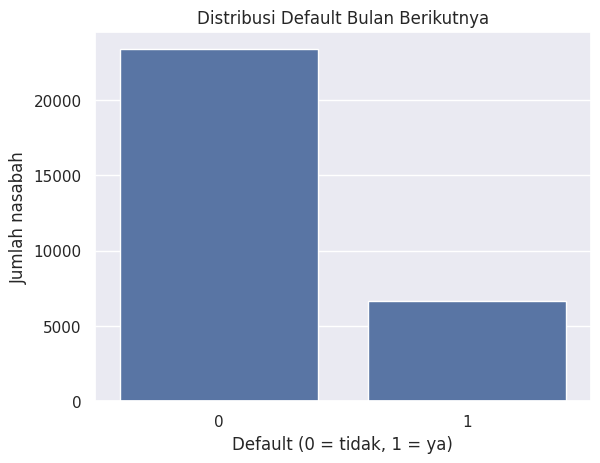

In [6]:
# CELL 6 — Analisis distribusi target
target_summary = pd.DataFrame({
    "jumlah": df["default_next_month"].value_counts().sort_index(),
    "persentase": (df["default_next_month"].value_counts(normalize=True).sort_index() * 100).round(2)
})
display(target_summary)
sns.countplot(data=df, x="default_next_month")
plt.title("Distribusi Default Bulan Berikutnya")
plt.xlabel("Default (0 = tidak, 1 = ya)")
plt.ylabel("Jumlah nasabah")
plt.show()


,PAY_0,jumlah_nasabah,tingkat_gagal_bayar,tingkat_gagal_bayar_persen
0,-2,2759,0.132294,13.229431
1,-1,5686,0.167781,16.778051
2,0,14737,0.128113,12.811291
3,1,3688,0.339479,33.947939
4,2,2667,0.691414,69.141357
5,3,322,0.757764,75.776398
6,4,76,0.684211,68.421053
7,5,26,0.500000,50.000000
8,6,11,0.545455,54.545455
9,7,9,0.777778,77.777778


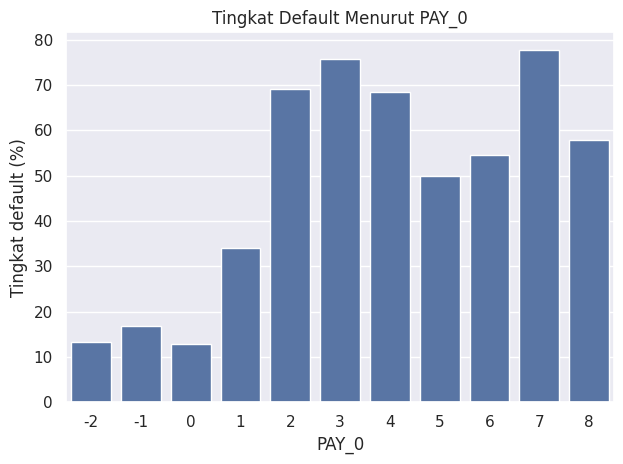

In [7]:
# CELL 7 — Tingkat gagal bayar berdasarkan PAY_0
pay_summary = (
    df.groupby("PAY_0")["default_next_month"]
      .agg(jumlah_nasabah="size", tingkat_gagal_bayar="mean")
      .reset_index()
)
pay_summary["tingkat_gagal_bayar_persen"] = pay_summary["tingkat_gagal_bayar"] * 100
display(pay_summary.sort_values("PAY_0"))
sns.barplot(data=pay_summary, x="PAY_0", y="tingkat_gagal_bayar_persen")
plt.title("Tingkat Default Menurut PAY_0")
plt.xlabel("PAY_0")
plt.ylabel("Tingkat default (%)")
plt.tight_layout()
plt.show()


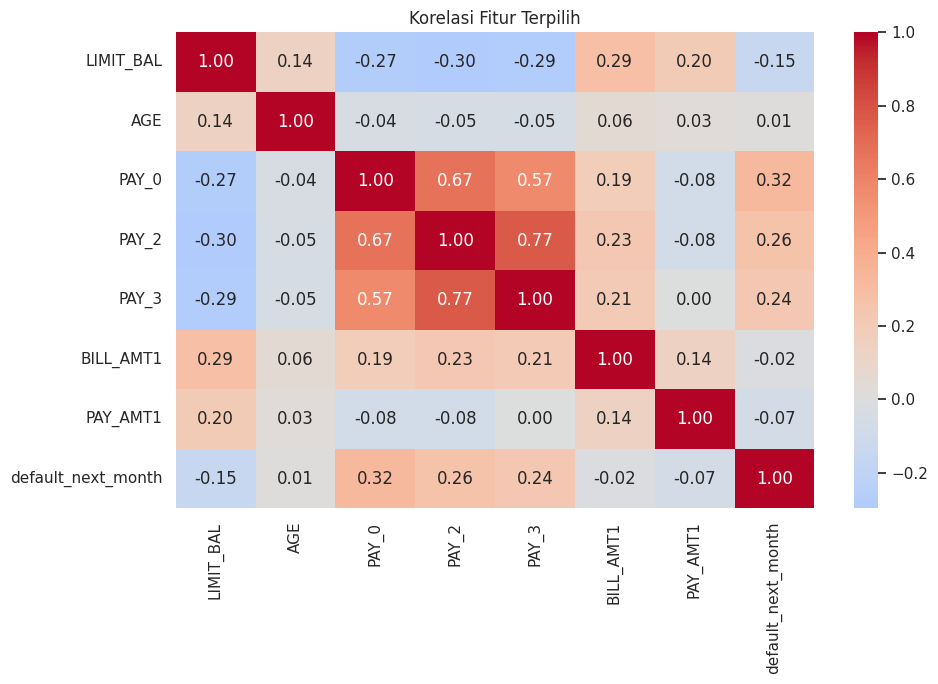

In [8]:
# CELL 8 — Korelasi beberapa fitur terpilih
corr_cols = ["LIMIT_BAL", "AGE", "PAY_0", "PAY_2", "PAY_3",
             "BILL_AMT1", "PAY_AMT1", "default_next_month"]
plt.figure(figsize=(10, 7))
sns.heatmap(df[corr_cols].corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelasi Fitur Terpilih")
plt.tight_layout()
plt.show()


In [9]:
# CELL 9 — Siapkan fitur dan target
X = df.drop(columns=["default_next_month"])
y = df["default_next_month"].astype(int)
categorical_cols = ["SEX", "EDUCATION", "MARRIAGE"]
numeric_cols = [c for c in X.columns if c not in categorical_cols]
print("Jumlah fitur:", X.shape[1])
print("Fitur kategorikal:", categorical_cols)
print("Jumlah fitur numerik:", len(numeric_cols))


Jumlah fitur: 23
Fitur kategorikal: ['SEX', 'EDUCATION', 'MARRIAGE']
Jumlah fitur numerik: 20


In [10]:
# CELL 10 — Bagi data menjadi train, validation, dan test
# 60% train, 20% validation, 20% test; stratify menjaga proporsi kelas.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=RANDOM_STATE, stratify=y
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)
print("Train:", X_train.shape, "Validation:", X_valid.shape, "Test:", X_test.shape)
display(y_train.value_counts(normalize=True).rename("proporsi target train"))


Train: (18000, 23) Validation: (6000, 23) Test: (6000, 23)


,proporsi target train
default_next_month,
0,0.778778
1,0.221222


In [11]:
# CELL 11 — Buat preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("numeric", StandardScaler(), numeric_cols),
    ],
    remainder="drop"
)


In [12]:
# CELL 12 — Siapkan model Logistic Regression dan Random Forest
models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=300, class_weight="balanced_subsample",
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ])
}
print("Model:", list(models.keys()))


Model: ['Logistic Regression', 'Random Forest']


In [13]:
# CELL 13 — Latih model
for name, model in models.items():
    print("Melatih", name)
    model.fit(X_train, y_train)
print("Pelatihan selesai.")


Melatih Logistic Regression
Melatih Random Forest
Pelatihan selesai.


In [14]:
# CELL 14 — Bandingkan model pada validation set
def evaluate_model(model, X_eval, y_eval):
    pred = model.predict(X_eval)
    prob = model.predict_proba(X_eval)[:, 1]
    return {
        "accuracy": accuracy_score(y_eval, pred),
        "precision": precision_score(y_eval, pred, zero_division=0),
        "recall": recall_score(y_eval, pred, zero_division=0),
        "f1_score": f1_score(y_eval, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_eval, prob),
    }

validation_results = {name: evaluate_model(model, X_valid, y_valid) for name, model in models.items()}
validation_df = pd.DataFrame(validation_results).T.sort_values("f1_score", ascending=False)
display(validation_df.round(4))


,accuracy,precision,recall,f1_score,roc_auc
Logistic Regression,0.6858,0.3732,0.6187,0.4656,0.7050
Random Forest,0.8080,0.6292,0.3210,0.4251,0.7601


In [15]:
# CELL 15 — Pilih model terbaik berdasarkan F1 validation
# Test set tidak digunakan untuk memilih model.
best_model_name = validation_df["f1_score"].idxmax()
best_model = models[best_model_name]
print("Model terpilih:", best_model_name)
print("F1-score validation:", round(validation_df.loc[best_model_name, "f1_score"], 4))


Model terpilih: Logistic Regression
F1-score validation: 0.4656


In [16]:
# CELL 16 — Evaluasi akhir pada test set
y_test_pred = best_model.predict(X_test)
y_test_prob = best_model.predict_proba(X_test)[:, 1]
test_metrics = {
    "accuracy": accuracy_score(y_test, y_test_pred),
    "precision": precision_score(y_test, y_test_pred, zero_division=0),
    "recall": recall_score(y_test, y_test_pred, zero_division=0),
    "f1_score": f1_score(y_test, y_test_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_test, y_test_prob),
}
display(pd.DataFrame([test_metrics], index=[best_model_name]).round(4))
print(classification_report(
    y_test, y_test_pred,
    target_names=["Tidak default (0)", "Default (1)"],
    zero_division=0
))


,accuracy,precision,recall,f1_score,roc_auc
Logistic Regression,0.694,0.3853,0.6443,0.4822,0.7288


                   precision    recall  f1-score   support

Tidak default (0)       0.88      0.71      0.78      4673
      Default (1)       0.39      0.64      0.48      1327

         accuracy                           0.69      6000
        macro avg       0.63      0.68      0.63      6000
     weighted avg       0.77      0.69      0.72      6000



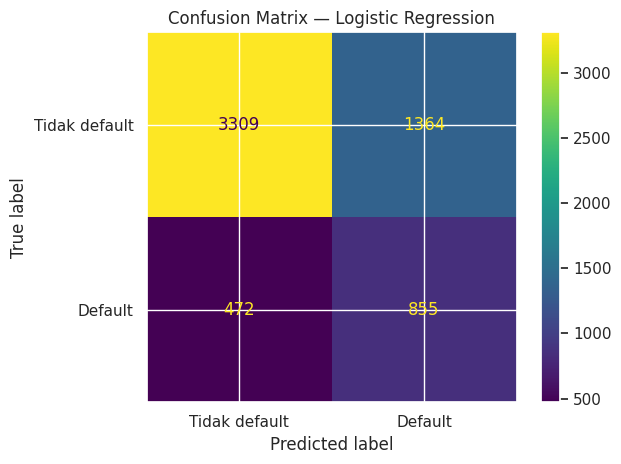

In [17]:
# CELL 17 — Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred,
    display_labels=["Tidak default", "Default"],
    values_format="d"
)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()


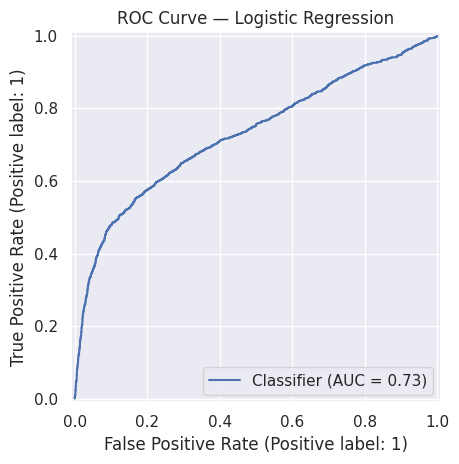

In [18]:
# CELL 18 — ROC curve
RocCurveDisplay.from_predictions(y_test, y_test_prob)
plt.title(f"ROC Curve — {best_model_name}")
plt.tight_layout()
plt.show()


In [19]:
# CELL 19 — Feature importance jika model terbaik adalah Random Forest
feature_importance_df = pd.DataFrame()
if best_model_name == "Random Forest":
    fitted_preprocessor = best_model.named_steps["preprocessor"]
    fitted_model = best_model.named_steps["model"]
    feature_importance_df = pd.DataFrame({
        "feature": fitted_preprocessor.get_feature_names_out(),
        "importance": fitted_model.feature_importances_
    }).sort_values("importance", ascending=False).reset_index(drop=True)
    display(feature_importance_df.head(15))
    sns.barplot(data=feature_importance_df.head(15), x="importance", y="feature")
    plt.title("15 Fitur Teratas — Random Forest")
    plt.tight_layout()
    plt.show()
else:
    print("Feature importance bawaan tidak tersedia untuk Logistic Regression pada cell ini.")


Feature importance bawaan tidak tersedia untuk Logistic Regression pada cell ini.


In [20]:
# CELL 20 — Contoh prediksi satu baris test set
sample = X_test.iloc[[0]]
actual_label = int(y_test.iloc[0])
predicted_label = int(best_model.predict(sample)[0])
predicted_probability = float(best_model.predict_proba(sample)[0, 1])
print("Label aktual:", actual_label)
print("Prediksi model:", predicted_label)
print(f"Probabilitas default yang diprediksi: {predicted_probability:.2%}")
display(sample)


Label aktual: 1
Prediksi model: 1
Probabilitas default yang diprediksi: 82.54%


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
12997,50000,1,2,2,30,2,2,2,2,2,-2,200,200,200,200,-200,0,0,0,0,0,200,0


In [21]:
# CELL 21 — Simpan model dan metrik
output_dir = Path("hasil_project")
output_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(best_model, output_dir / "best_payment_default_model.joblib")
validation_df.to_csv(output_dir / "validation_model_comparison.csv", index=True)
pd.DataFrame([test_metrics], index=[best_model_name]).to_csv(output_dir / "test_metrics.csv", index=True)
if not feature_importance_df.empty:
    feature_importance_df.to_csv(output_dir / "feature_importance.csv", index=False)

summary = {
    "dataset": "UCI Default of Credit Card Clients",
    "uci_dataset_id": 350,
    "selected_model": best_model_name,
    "selection_metric": "F1-score pada validation set",
    "test_metrics": test_metrics,
    "random_state": RANDOM_STATE,
    "note": "Dataset ini memprediksi default pembayaran kartu kredit, bukan keterlambatan invoice."
}
with open(output_dir / "model_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)
print("Hasil tersimpan di:", output_dir.resolve())
print([p.name for p in output_dir.iterdir()])


Hasil tersimpan di: /content/hasil_project
['test_metrics.csv', 'model_summary.json', 'best_payment_default_model.joblib', 'validation_model_comparison.csv']


In [22]:
# CELL 22 — Buat ZIP artefak hasil analisis
import zipfile
zip_path = Path("hasil_project.zip")
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for file_path in output_dir.rglob("*"):
        if file_path.is_file():
            zf.write(file_path, arcname=str(file_path))
print("ZIP dibuat:", zip_path.resolve())


ZIP dibuat: /content/hasil_project.zip


In [24]:

# CELL — Buat ZIP hasil proyek
import os
import shutil
from google.colab import files

folder = "/content/hasil_project"

if os.path.isdir(folder):
    file_zip = shutil.make_archive(
        "/content/hasil_proyek",
        "zip",
        root_dir=folder
    )
    files.download(file_zip)
else:
    print("Folder hasil_project belum ditemukan.")
    print("Jalankan cell penyimpanan hasil model terlebih dahulu.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>